In [ ]:
!pip install -q langchain langchain-groq gspread

import os
from google.colab import userdata, auth
os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")

from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-20b", temperature=0.2, max_retries=3)

auth.authenticate_user()
import gspread
from google.auth import default
creds, _ = default()
gc = gspread.authorize(creds)
sh = gc.create("Sweet Crumbs Orders")      # run once; next time use gc.open("Sweet Crumbs Orders")
ws = sh.sheet1
ws.append_row(["name", "item", "qty", "date", "eggless", "total"])
print("Sheet ready:", sh.url)

Sheet ready: https://docs.google.com/spreadsheets/d/10RmLdB6M3omWLNJBrtwzW75W89YvsR6EK1yzvLZmKVc


In [ ]:
from typing import Literal
from pydantic import BaseModel, Field
from langchain.tools import tool

MENU = {"plum cake": 500, "chocolate cake": 650, "cupcake": 80}
HOURS = {"monday": "9 am to 8 pm", "tuesday": "9 am to 8 pm", "wednesday": "9 am to 8 pm",
         "thursday": "9 am to 8 pm", "friday": "9 am to 8 pm", "saturday": "9 am to 8 pm",
         "sunday": "10 am to 6 pm"}

class Order(BaseModel):
    """A cake order taken from a customer's chat message."""
    name: str = Field(description="Customer's first name")
    item: Literal["plum cake", "chocolate cake", "cupcake"] = Field(description="Menu item")
    qty: int = Field(description="How many", ge=1)
    date: str = Field(description="Pickup date as the customer said it")
    eggless: bool = Field(description="True if the customer asked for eggless")


In [ ]:
@tool
def get_price(item: str, qty: int = 1) -> str:
    """Get the total price in rupees for a quantity of one menu item.

    Args:
        item: Menu item, e.g. "plum cake", "chocolate cake" or "cupcake"
        qty: How many the customer wants
    """
    price = MENU.get(item.lower().strip())
    if price is None:
        return f"'{item}' is not on the menu. We have: {', '.join(MENU)}."
    return f"{qty} x {item} = Rs {price * qty}"

@tool
def is_open(day: str) -> str:
    """Check the bakery's opening hours for a day of the week, e.g. "sunday"."""
    hours = HOURS.get(day.lower().strip())
    return f"Open {hours} on {day}." if hours else f"'{day}' is not a day of the week."

@tool
def log_order(name: str, item: str, qty: int, date: str, eggless: bool) -> str:
    """Save a confirmed cake order to the Orders sheet.
    Use only when the customer has given their name, item, quantity and pickup date."""
    try:
        order = Order(name=name, item=item.lower().strip(), qty=qty, date=date, eggless=eggless)
    except Exception as e:
        return f"Could not save the order: {e}. Ask the customer to correct it."
    total = MENU[order.item] * order.qty
    ws.append_row([order.name, order.item, order.qty, order.date,
                   "yes" if order.eggless else "no", total])
    return f"Saved: {order.qty} x {order.item} for {order.name} on {order.date}, Rs {total}."

In [ ]:
from langchain.agents import create_agent

SYSTEM = """ROLE:   You are the friendly order assistant for Sweet Crumbs Home Bakery.
FACTS:  Orders need 24 hours' notice. All cakes have eggless versions.
RULES:  Always use get_price for prices and is_open for timings; never guess them.
        Before log_order, make sure you have name, item, quantity and pickup date; ask if missing.
        After saving, read the order back with the total.
FORMAT: Under 60 words, friendly, English or Telugu matching the customer."""

agent = create_agent(model=llm, tools=[get_price, is_open, log_order], system_prompt=SYSTEM)

history = []
def chat(text: str) -> str:
    global history
    try:
        result = agent.invoke({"messages": history + [{"role": "user", "content": text}]})
        history = result["messages"]                  # keep the whole run as memory
        return history[-1].content
    except Exception as e:
        print("Agent error:", e)
        return "Sorry, I'm a little busy. Please try again in a minute."

print(chat("Are you open on Sunday? How much are 2 chocolate cakes?"))
print(chat("I'm Ravi. Please book 2 eggless chocolate cakes for 24 Dec."))

Yes! We’re open Sunday from 10 am to 6 pm. Two chocolate cakes will cost ₹1,300. Let me know your name, pickup date, and if you’d like the egg‑less version, and I’ll log the order for you.
All set, Ravi! Your 2 egg‑less chocolate cakes are booked for pickup on 24 Dec. Total: ₹1,300. We’ll see you then—happy baking!


In [ ]:
for m in history:
    m.pretty_print()


================================ Human Message =================================

Are you open on Sunday? How much are 2 chocolate cakes?
================================== Ai Message ==================================
Tool Calls:
  is_open (fc_0ab7b8eb-8058-4e25-8c87-252f0bf21ba7)
 Call ID: fc_0ab7b8eb-8058-4e25-8c87-252f0bf21ba7
  Args:
    day: sunday
================================= Tool Message =================================
Name: is_open

Open 10 am to 6 pm on sunday.
================================== Ai Message ==================================
Tool Calls:
  get_price (fc_4723b1bb-2a93-4bd1-91ce-708853576016)
 Call ID: fc_4723b1bb-2a93-4bd1-91ce-708853576016
  Args:
    item: chocolate cake
    qty: 2
================================= Tool Message =================================
Name: get_price

2 x chocolate cake = Rs 1300
================================== Ai Message ==================================

Yes! We’re open Sunday from 10 am to 6 pm. Two chocolate cakes will

In [ ]:
print(chat("Do you have donuts?"))
print(chat("Book 2 plum cakes for Kiran."))
print(chat("Book 0 cupcakes for Kiran on 25 Dec."))

Sorry, we don’t have donuts in our menu. But we offer a variety of cakes, cupcakes, and pastries—happy to help you pick something else!
Sure thing, Kiran! Just let me know the pickup date and whether you’d like the egg‑less version. Then I’ll lock it in.
I’m happy to help, Kiran! Just to confirm, you’d like 0 cupcakes on 25 Dec? Usually we need at least one item to place an order. Could you let me know the correct quantity?


In [ ]:
class Appointment(BaseModel):
    """A patient appointment booking for Surya Homoeo Clinic."""
    patient_name: str = Field(description="Patient's full or first name")
    branch: Literal["kakinada", "pithapuram"] = Field(description="Clinic branch city")
    day: str = Field(description="Preferred day or date of visit, e.g. 'Wednesday' or '28 Nov'")
    is_followup: bool = Field(description="True if this is a follow-up visit, False if new consultation")
    medicine_weeks: int = Field(description="Weeks of medicine requested", ge=0, default=1)

extractor = llm.with_structured_output(Appointment)

messy_messages = [
    "hi im suresh need appointment at kakinada branch on wednesday first time visit",
    "Anitha here, follow up visit at pithapuram this friday, need 2 weeks medicine",
    "book slot for ramesh in kakinada tomorrow new consultation 1 week meds",
    "hello doctor meena coming to pitapuram on saturday for followup no medicine needed",
    "can u book karthik at kakinada on monday 3 weeks medicine new patient"
]

for msg in messy_messages:
    print(extractor.invoke(msg))

patient_name='Suresh' branch='kakinada' day='Wednesday' is_followup=False medicine_weeks=1
patient_name='Anitha' branch='pithapuram' day='Friday' is_followup=True medicine_weeks=2
patient_name='ramesh' branch='kakinada' day='tomorrow' is_followup=False medicine_weeks=1
patient_name='doctor meena' branch='pithapuram' day='Saturday' is_followup=True medicine_weeks=0
patient_name='karthik' branch='kakinada' day='Monday' is_followup=False medicine_weeks=3


In [ ]:
clinic_sh = gc.create("Surya Homoeo Appointments")   # run once; later use gc.open("Surya Homoeo Appointments")
clinic_ws = clinic_sh.sheet1
clinic_ws.clear()
clinic_ws.append_row([
    "patient_name",
    "branch",
    "day",
    "new_month",
    "medicines_for_month",
    "estimated_cost"
])
print("Updated sheet headers successfully!")

print("Clinic Sheet ready:", clinic_sh.url)

@tool
def log_appointment(patient_name: str, branch: str, day: str, is_followup: bool, medicine_weeks: int = 1) -> str:
    """Save a confirmed patient appointment to the Surya Homoeo Appointments sheet.
    Use only when patient_name, branch ('kakinada' or 'pithapuram'), day, and whether it is a follow-up are known."""
    try:
        appt = Appointment(
            patient_name=patient_name,
            branch=branch.lower().strip(),
            day=day,
            is_followup=is_followup,
            medicine_weeks=medicine_weeks
        )
    except Exception as e:
        return f"Could not save appointment: {e}. Ask the patient to clarify."

    consult_min, consult_max = (0, 0) if appt.is_followup else (200, 300)
    est_cost = f"Rs {consult_min + appt.medicine_weeks * 700}-{consult_max + appt.medicine_weeks * 800}"
    clinic_ws.append_row([
        appt.patient_name, appt.branch, appt.day,
        "yes" if appt.is_followup else "no", appt.medicine_weeks, est_cost
    ])
    return f"Booked: {appt.patient_name} at {appt.branch.title()} on {appt.day} ({est_cost})."

Updated sheet headers successfully!
Clinic Sheet ready: https://docs.google.com/spreadsheets/d/15trokf3juquTKRS4tn3QjZiuNpBFH9e6qP7wJZagxGE


In [ ]:
@tool
def estimate_clinic_cost(is_same_month_followup: bool, medicine_months: int = 1) -> str:
    """Estimate total cost in Rs for Surya Homoeo Clinic.
    Use when a patient asks about consultation fees, follow-up fees, or monthly medicine costs.

    Args:
        is_same_month_followup: True if the patient already visited within the current month (free consultation).
        medicine_months: Number of months of homeopathic medicine needed (default 1).
    """
    consult_min, consult_max = (0, 0) if is_same_month_followup else (200, 300)
    total_min = consult_min + medicine_months * 700
    total_max = consult_max + medicine_months * 800
    return (
        f"Estimated total: Rs {total_min} to Rs {total_max} "
        f"(monthly medicines usually cost Rs 700–800/month and depend on the patient's health problem)."
    )

@tool
def get_branch_timings(branch: str, day: str) -> str:
    """Check operating hours for Surya Homoeo Clinic at 'kakinada' or 'pithapuram' on a given day of the week."""
    b, d = branch.strip().lower(), day.strip().lower()
    if d == "sunday":
        return "Both Kakinada and Pithapuram branches are closed on Sundays."
    if b == "kakinada":
        return "Kakinada timings: 10:00 AM to 2:30 PM" if d == "wednesday" else "Kakinada timings: 4:00 PM to 9:30 PM"
    if b == "pithapuram":
        return "Pithapuram timings: 4:00 PM to 9:00 PM" if d == "wednesday" else "Pithapuram timings: 10:00 AM to 2:30 PM"
    return f"'{branch}' is not a valid branch. Available branches: Kakinada and Pithapuram."

In [ ]:
CLINIC_SYSTEM = """ROLE:   You are the polite front-desk assistant for Surya Homoeo Clinic.
FACTS:  Branches in Kakinada and Pithapuram. Closed on Sundays. Same-month follow-ups are free.
RULES:  Always use get_branch_timings for hours and estimate_clinic_cost for fees; never guess.
        Never diagnose symptoms or suggest medicines; say "Consult doctor as soon as possible."
        Before log_appointment, collect patient_name, branch, day, and whether it is a follow-up.
FORMAT: Under 60 words, calm and polite, English or Telugu matching the patient."""

clinic_agent = create_agent(
    model=llm,
    tools=[get_branch_timings, estimate_clinic_cost, log_appointment],
    system_prompt=CLINIC_SYSTEM
)

res = clinic_agent.invoke({"messages": [{"role": "user", "content": "What are Kakinada timings on Wednesday, and book a new visit for Tharun on Wednesday with 1 week medicine."}]})

for m in res["messages"]:
    m.pretty_print()

================================ Human Message =================================

What are Kakinada timings on Wednesday, and book a new visit for Tharun on Wednesday with 1 week medicine.
================================== Ai Message ==================================
Tool Calls:
  get_branch_timings (fc_62de08dd-319c-4d0b-8f87-e80ff8ec7b46)
 Call ID: fc_62de08dd-319c-4d0b-8f87-e80ff8ec7b46
  Args:
    branch: kakinada
    day: Wednesday
================================= Tool Message =================================
Name: get_branch_timings

Kakinada timings: 10:00 AM to 2:30 PM
================================== Ai Message ==================================
Tool Calls:
  log_appointment (fc_efbd258f-c68f-47a7-9a95-64d2f0eb1e1f)
 Call ID: fc_efbd258f-c68f-47a7-9a95-64d2f0eb1e1f
  Args:
    branch: kakinada
    day: Wednesday
    is_followup: False
    medicine_weeks: 1
    patient_name: Tharun
================================= Tool Message =================================
Name: log_

In [26]:
!pip install -q sentence-transformers langchain-huggingface
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")

# 1. Sweet Crumbs Home Bakery FAQs
FAQS = {
    "delivery":     "We deliver within 5 km of the bakery. Delivery is Rs 50, free for orders above Rs 1,000.",
    "payment":      "We accept UPI and cash. Orders above Rs 1,000 need a 50% advance by UPI.",
    "cancellation": "Cancellation is free up to 12 hours before pickup. After that, the advance is not refunded.",
    "photo_cake":   "Photo cakes and custom designs need 48 hours' notice.",
    "notice":       "Regular orders need 24 hours' notice.",
    "eggless":      "All our cakes have eggless versions at the same price.",
    "allergens":    "Plum cake contains nuts and dried fruit. Cupcakes and chocolate cake are nut-free.",
    "storage":      "Keep cakes in the fridge and eat them within 3 days.",
    "message":      "A message on the cake is free, up to 20 letters.",
    "candles":      "Candles are free with every cake.",
    "discounts":    "Bulk-order discounts need the owner's approval.",
    "pickup":       "Pickup is during opening hours: Monday to Saturday 9 am to 8 pm, Sunday 10 am to 6 pm.",
}

faq_store = InMemoryVectorStore.from_texts(list(FAQS.values()), embeddings)

@tool
def search_faq(question: str) -> str:
    """Search Sweet Crumbs' policies and FAQs: delivery, payment, cancellation,
    photo cakes, allergens, storage, candles and messages on cakes.
    Use for any question about rules or policies, not for prices or opening hours."""
    docs = faq_store.similarity_search(question, k=3)
    return "\n".join(d.page_content for d in docs)

# 2. Surya Homoeo Clinic FAQs
CLINIC_FAQS = {
    "branches": "Surya Homoeo Clinic has two branches: Kakinada and Pithapuram.",
    "sunday_closed": "Both Kakinada and Pithapuram branches are closed on Sundays.",
    "kakinada_hours": "Kakinada branch timings: Mon-Tue 4:00 PM to 9:30 PM, Wed 10:00 AM to 2:30 PM, Thu-Sat 4:00 PM to 9:30 PM.",
    "pithapuram_hours": "Pithapuram branch timings: Mon-Tue 10:00 AM to 2:30 PM, Wed 4:00 PM to 9:00 PM, Thu-Sat 10:00 AM to 2:30 PM.",
    "new_consultation": "New consultation or new-month visit fee is Rs 200 to Rs 300.",
    "followup_policy": "Follow-up visits within the same calendar month are completely free.",
    "medicine_cost": "Monthly homeopathic medicines usually cost Rs 700 to Rs 800, depending upon the patient's health problem.",
    "chronic_treatment": "Chronic conditions like migraine, skin allergies, asthma, and arthritis are treated with personalized constitutional remedies.",
    "medicine_safety": "Homeopathic medicines are gentle, non-habit forming, and safe for children and elderly patients when taken as prescribed.",
    "diet_rules": "Patients should avoid strong coffee, raw onion, raw garlic, and mint 30 minutes before and after taking homeopathic doses.",
    "storage_rules": "Store homeopathic pills in a cool, dry place away from direct sunlight and strong perfumes.",
    "payment_modes": "Both clinic branches accept cash and UPI payments (GPay, PhonePe, Paytm).",
    "walkin_policy": "Walk-in patients are welcome during branch hours, though prior slot booking reduces waiting time.",
    "online_consult": "Follow-up consultations can be arranged over phone or WhatsApp for outstation patients with courier medicine delivery.",
    "emergency_policy": "For acute medical emergencies, high fever with distress, or severe injuries, visit the nearest emergency hospital immediately."
}

clinic_faq_store = InMemoryVectorStore.from_texts(list(CLINIC_FAQS.values()), embeddings)

@tool
def search_clinic_faq(question: str) -> str:
    """Search Surya Homoeo Clinic policies, FAQs, diet rules, medicine storage, payment modes, online consultations, and treatment info.
    Use for any policy, diet, payment, or general clinic FAQ—not for checking branch hours or calculating fees."""
    docs = clinic_faq_store.similarity_search(question, k=3)
    return "\n".join(d.page_content for d in docs)

print("Both FAQ vector stores ready!")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Both FAQ vector stores ready!


In [ ]:
@tool
def search_faq(question: str) -> str:
    """Search Sweet Crumbs' policies and FAQs: delivery, payment, cancellation,
    photo cakes, allergens, storage, candles and messages on cakes.
    Use for any question about rules or policies, not for prices or opening hours."""
    results = faq.query(query_texts=[question], n_results=3)
    return "\n".join(results["documents"][0])

In [ ]:
from langgraph.checkpoint.memory import InMemorySaver
from langchain.agents import create_agent

SYSTEM = """ROLE:   You are the friendly assistant for Sweet Crumbs Home Bakery.
RULES:  Use get_price for prices and is_open for timings; never guess them.
        For any policy question, use search_faq and answer ONLY from what it returns.
        If the answer isn't there, say "I'll check with the owner."
        Before log_order, make sure you have name, item, quantity and pickup date; ask if missing.
FORMAT: Under 60 words, friendly, English or Telugu matching the customer."""

agent = create_agent(
    model=llm,
    tools=[get_price, is_open, log_order, search_faq],
    system_prompt=SYSTEM,
    checkpointer=InMemorySaver()
)

def chat(thread_id: str, text: str) -> str:
    config = {"configurable": {"thread_id": thread_id}}
    try:
        result = agent.invoke({"messages": [{"role": "user", "content": text}]}, config)
        return result["messages"][-1].content
    except Exception as e:
        print("Agent error:", e)
        return "Sorry, I'm a little busy. Please try again in a minute."

print(chat("ravi", "Hi, I'm Ravi. Do you deliver? My order is about Rs 1,300."))
print(chat("ravi", "Does the plum cake have nuts?"))
print(chat("sravani", "Can I cancel tomorrow morning if I pick up tomorrow evening?"))
print(chat("ravi", "What's my name, and will I pay for delivery?"))

Agent error: name 'faq' is not defined
Sorry, I'm a little busy. Please try again in a minute.
Agent error: name 'faq' is not defined
Sorry, I'm a little busy. Please try again in a minute.
Agent error: name 'faq' is not defined
Sorry, I'm a little busy. Please try again in a minute.
Agent error: name 'faq' is not defined
Sorry, I'm a little busy. Please try again in a minute.


In [ ]:
%%writefile -a tests.csv
Do you deliver?,5 km
Is the plum cake nut-free?,nuts
How much notice for a photo cake?,48
Can I pay by UPI?,UPI
Do you sell biryani?,check with the owner

Writing tests.csv


In [28]:
@tool
def search_clinic_faq(question: str) -> str:
    """Search Surya Homoeo Clinic policies, FAQs, diet rules, medicine storage, payment modes, online consultations, and treatment info.
    Use for any policy, diet, payment, or general clinic FAQ—not for checking branch hours or calculating fees."""
    results = clinic_faq.query(query_texts=[question], n_results=3)
    return "\n".join(results["documents"][0])

In [29]:
CLINIC_SYSTEM_V2 = """ROLE:   You are the polite front-desk assistant for Surya Homoeo Clinic.
RULES:  Use get_branch_timings for hours and estimate_clinic_cost for fees; never guess.
        For any clinic policy, diet, storage, payment, or general FAQ, use search_clinic_faq and answer ONLY from what it returns.
        If the answer is not in the retrieved facts, say "I'll check with the doctor."
        Never diagnose symptoms or prescribe medicines; for medical advice say "Consult doctor as soon as possible."
        Before log_appointment, collect patient_name, branch, day, new_month, and medicines_for_month.
FORMAT: Under 60 words, calm and polite, English or Telugu matching the patient."""

clinic_agent = create_agent(
    model=llm,
    tools=[get_branch_timings, estimate_clinic_cost, log_appointment, search_clinic_faq],
    system_prompt=CLINIC_SYSTEM_V2,
    checkpointer=InMemorySaver()
)

def chat_clinic(thread_id: str, text: str) -> str:
    config = {"configurable": {"thread_id": thread_id}}
    try:
        res = clinic_agent.invoke({"messages": [{"role": "user", "content": text}]}, config)
        return res["messages"][-1].content
    except Exception as e:
        print("Clinic Agent error:", e)
        return "Sorry, the desk is busy right now. Please try again in a minute."

print("Tharun 1:", chat_clinic("tharun", "Hi, I'm Tharun. Can I drink coffee while taking homeopathy medicines?"))
print("Anitha 1:", chat_clinic("anitha", "Hello, do you accept GPay at the clinic?"))
print("Tharun 2:", chat_clinic("tharun", "What is my name, and how should I store the pills?"))

Clinic Agent error: name 'clinic_faq' is not defined
Tharun 1: Sorry, the desk is busy right now. Please try again in a minute.
Clinic Agent error: name 'clinic_faq' is not defined
Anitha 1: Sorry, the desk is busy right now. Please try again in a minute.
Clinic Agent error: name 'clinic_faq' is not defined
Tharun 2: Sorry, the desk is busy right now. Please try again in a minute.


In [30]:
print("Out of scope:", chat_clinic("test_oos", "Do you offer dental X-rays or blood tests at the clinic?"))

Clinic Agent error: name 'clinic_faq' is not defined
Out of scope: Sorry, the desk is busy right now. Please try again in a minute.


In [31]:
signoff_tests = [
    ("How much is a new consultation?", "200"),
    ("Is a follow-up in the same month free?", "free"),
    ("What are Kakinada timings on Wednesday?", "10:00 AM"),
    ("Can I drink coffee during homeopathy treatment?", "30 minutes"),
    ("How should I store the homeopathy pills?", "cool"),
    ("Do you accept UPI payments?", "UPI"),
    ("Do you have an MRI scan facility?", "check with the doctor"),
]

passed = 0
for idx, (q, expected) in enumerate(signoff_tests):
    ans = chat_clinic(f"signoff_{idx}", q)
    ok = expected.lower() in ans.lower().replace("\u202f", " ")
    passed += ok
    print("PASS" if ok else "FAIL", "|", q, "→", ans[:75])

print(f"\nSingle-Agent Sign-Off Score: {passed}/{len(signoff_tests)} ({passed/len(signoff_tests):.0%})")

Clinic Agent error: name 'clinic_faq' is not defined
FAIL | How much is a new consultation? → Sorry, the desk is busy right now. Please try again in a minute.
Clinic Agent error: name 'clinic_faq' is not defined
FAIL | Is a follow-up in the same month free? → Sorry, the desk is busy right now. Please try again in a minute.
PASS | What are Kakinada timings on Wednesday? → Kakinada branch is open on Wednesdays from 10:00 AM to 2:30 PM.
Clinic Agent error: name 'clinic_faq' is not defined
FAIL | Can I drink coffee during homeopathy treatment? → Sorry, the desk is busy right now. Please try again in a minute.
Clinic Agent error: name 'clinic_faq' is not defined
FAIL | How should I store the homeopathy pills? → Sorry, the desk is busy right now. Please try again in a minute.
Clinic Agent error: name 'clinic_faq' is not defined
FAIL | Do you accept UPI payments? → Sorry, the desk is busy right now. Please try again in a minute.
Clinic Agent error: name 'clinic_faq' is not defined
FAIL | Do y

In [ ]:
!pip install -q --upgrade opentelemetry-api==1.27.0 opentelemetry-sdk==1.27.0 opentelemetry-exporter-otlp-proto-grpc==1.27.0 chromadb

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opentelemetry-exporter-otlp-common 0.66b2 requires opentelemetry-sdk~=1.45.2, but you have opentelemetry-sdk 1.27.0 which is incompatible.
google-cloud-bigquery-connection 1.23.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 4.25.9 which is incompatible.
google-cloud-resource-manager 1.19.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 4.25.9 which is incompatible.
opentelemetry-resourcedetector-gcp 1.14.0 requires opentelemetry-api~=1.30, but you have opentelemetry-api 1.27.0 which is incompatible.
opentelemetry-resourcedetector-gcp 1.14.0 requires opentelemetry-sdk~=1.30, but you have opentelemetry-sdk 1.27.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.27.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sd

In [33]:
!pip install -q sentence-transformers langchain-huggingface
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")

# 1. Sweet Crumbs Home Bakery FAQs
FAQS = {
    "delivery":     "We deliver within 5 km of the bakery. Delivery is Rs 50, free for orders above Rs 1,000.",
    "payment":      "We accept UPI and cash. Orders above Rs 1,000 need a 50% advance by UPI.",
    "cancellation": "Cancellation is free up to 12 hours before pickup. After that, the advance is not refunded.",
    "photo_cake":   "Photo cakes and custom designs need 48 hours' notice.",
    "notice":       "Regular orders need 24 hours' notice.",
    "eggless":      "All our cakes have eggless versions at the same price.",
    "allergens":    "Plum cake contains nuts and dried fruit. Cupcakes and chocolate cake are nut-free.",
    "storage":      "Keep cakes in the fridge and eat them within 3 days.",
    "message":      "A message on the cake is free, up to 20 letters.",
    "candles":      "Candles are free with every cake.",
    "discounts":    "Bulk-order discounts need the owner's approval.",
    "pickup":       "Pickup is during opening hours: Monday to Saturday 9 am to 8 pm, Sunday 10 am to 6 pm.",
}

faq_store = InMemoryVectorStore.from_texts(list(FAQS.values()), embeddings)

@tool
def search_faq(question: str) -> str:
    """Search Sweet Crumbs' policies and FAQs: delivery, payment, cancellation,
    photo cakes, allergens, storage, candles and messages on cakes.
    Use for any question about rules or policies, not for prices or opening hours."""
    docs = faq_store.similarity_search(question, k=3)
    return "\n".join(d.page_content for d in docs)

# 2. Surya Homoeo Clinic FAQs
CLINIC_FAQS = {
    "branches": "Surya Homoeo Clinic has two branches: Kakinada and Pithapuram.",
    "sunday_closed": "Both Kakinada and Pithapuram branches are closed on Sundays.",
    "kakinada_hours": "Kakinada branch timings: Mon-Tue 4:00 PM to 9:30 PM, Wed 10:00 AM to 2:30 PM, Thu-Sat 4:00 PM to 9:30 PM.",
    "pithapuram_hours": "Pithapuram branch timings: Mon-Tue 10:00 AM to 2:30 PM, Wed 4:00 PM to 9:00 PM, Thu-Sat 10:00 AM to 2:30 PM.",
    "new_consultation": "New consultation or new-month visit fee is Rs 200 to Rs 300.",
    "followup_policy": "Follow-up visits within the same calendar month are completely free.",
    "medicine_cost": "Monthly homeopathic medicines usually cost Rs 700 to Rs 800, depending upon the patient's health problem.",
    "chronic_treatment": "Chronic conditions like migraine, skin allergies, asthma, and arthritis are treated with personalized constitutional remedies.",
    "medicine_safety": "Homeopathic medicines are gentle, non-habit forming, and safe for children and elderly patients when taken as prescribed.",
    "diet_rules": "Patients should avoid strong coffee, raw onion, raw garlic, and mint 30 minutes before and after taking homeopathic doses.",
    "storage_rules": "Store homeopathic pills in a cool, dry place away from direct sunlight and strong perfumes.",
    "payment_modes": "Both clinic branches accept cash and UPI payments (GPay, PhonePe, Paytm).",
    "walkin_policy": "Walk-in patients are welcome during branch hours, though prior slot booking reduces waiting time.",
    "online_consult": "Follow-up consultations can be arranged over phone or WhatsApp for outstation patients with courier medicine delivery.",
    "emergency_policy": "For acute medical emergencies, high fever with distress, or severe injuries, visit the nearest emergency hospital immediately."
}

clinic_faq_store = InMemoryVectorStore.from_texts(list(CLINIC_FAQS.values()), embeddings)

@tool
def search_clinic_faq(question: str) -> str:
    """Search Surya Homoeo Clinic policies, FAQs, diet rules, medicine storage, payment modes, online consultations, and treatment info.
    Use for any policy, diet, payment, or general clinic FAQ—not for checking branch hours or calculating fees."""
    docs = clinic_faq_store.similarity_search(question, k=3)
    return "\n".join(d.page_content for d in docs)

print("Both FAQ vector stores ready!")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Both FAQ vector stores ready!


In [35]:
!pip install -q langchain langchain-groq langgraph gspread sentence-transformers langchain-huggingface

import os
import gspread
from google.colab import userdata, auth
from google.auth import default
from langchain_groq import ChatGroq

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
llm = ChatGroq(model="openai/gpt-oss-20b", temperature=0.2, max_retries=3)

auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# Open existing Google Sheets (or create if missing)
try:
    ws = gc.open("Sweet Crumbs Orders").sheet1
except gspread.SpreadsheetNotFound:
    ws = gc.create("Sweet Crumbs Orders").sheet1
    ws.append_row(["name", "item", "qty", "date", "eggless", "total"])

try:
    clinic_ws = gc.open("Surya Homoeo Appointments").sheet1
except gspread.SpreadsheetNotFound:
    clinic_ws = gc.create("Surya Homoeo Appointments").sheet1
    clinic_ws.append_row(["patient_name", "branch", "day", "new_month", "medicines_for_month", "estimated_cost"])

print("Setup complete & Google Sheets connected!")

Setup complete & Google Sheets connected!


In [36]:
!pip install -q langchain langchain-groq langgraph gspread sentence-transformers langchain-huggingface

import os
import gspread
from google.colab import userdata, auth
from google.auth import default
from langchain_groq import ChatGroq

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
llm = ChatGroq(model="openai/gpt-oss-20b", temperature=0.2, max_retries=3)

auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# Open existing Google Sheets (or create if missing)
try:
    ws = gc.open("Sweet Crumbs Orders").sheet1
except gspread.SpreadsheetNotFound:
    ws = gc.create("Sweet Crumbs Orders").sheet1
    ws.append_row(["name", "item", "qty", "date", "eggless", "total"])

try:
    clinic_ws = gc.open("Surya Homoeo Appointments").sheet1
except gspread.SpreadsheetNotFound:
    clinic_ws = gc.create("Surya Homoeo Appointments").sheet1
    clinic_ws.append_row(["patient_name", "branch", "day", "new_month", "medicines_for_month", "estimated_cost"])

print("Setup complete & Google Sheets connected!")

Setup complete & Google Sheets connected!


In [37]:
from typing import Literal
from pydantic import BaseModel, Field

# --- Sweet Crumbs Tools ---
MENU = {"plum cake": 500, "chocolate cake": 650, "cupcake": 80}
HOURS = {
    "monday": "9 am to 8 pm", "tuesday": "9 am to 8 pm", "wednesday": "9 am to 8 pm",
    "thursday": "9 am to 8 pm", "friday": "9 am to 8 pm", "saturday": "9 am to 8 pm",
    "sunday": "10 am to 6 pm"
}

class Order(BaseModel):
    """A cake order taken from a customer's chat message."""
    name: str = Field(description="Customer's first name")
    item: Literal["plum cake", "chocolate cake", "cupcake"] = Field(description="Menu item")
    qty: int = Field(description="How many", ge=1)
    date: str = Field(description="Pickup date as the customer said it")
    eggless: bool = Field(description="True if the customer asked for eggless")

@tool
def get_price(item: str, qty: int = 1) -> str:
    """Get the total price in rupees for a quantity of one menu item."""
    price = MENU.get(item.lower().strip())
    if price is None:
        return f"'{item}' is not on the menu. We have: {', '.join(MENU)}."
    return f"{qty} x {item} = Rs {price * qty}"

@tool
def is_open(day: str) -> str:
    """Check the bakery's opening hours for a day of the week, e.g. 'sunday'."""
    hours = HOURS.get(day.lower().strip())
    return f"Open {hours} on {day}." if hours else f"'{day}' is not a day of the week."

@tool
def log_order(name: str, item: str, qty: int, date: str, eggless: bool) -> str:
    """Save a confirmed cake order to the Orders sheet.
    Use only when the customer has given their name, item, quantity and pickup date."""
    try:
        order = Order(name=name, item=item.lower().strip(), qty=qty, date=date, eggless=eggless)
    except Exception as e:
        return f"Could not save the order: {e}. Ask the customer to correct it."
    total = MENU[order.item] * order.qty
    ws.append_row([order.name, order.item, order.qty, order.date, "yes" if order.eggless else "no", total])
    return f"Saved: {order.qty} x {order.item} for {order.name} on {order.date}, Rs {total}."

# --- Surya Homoeo Clinic Tools ---
class Appointment(BaseModel):
    """A patient appointment booking for Surya Homoeo Clinic."""
    patient_name: str = Field(description="Patient's full or first name")
    branch: Literal["kakinada", "pithapuram"] = Field(description="Clinic branch city")
    day: str = Field(description="Preferred day or date of visit, e.g. 'Wednesday' or '28 Nov'")
    new_month: bool = Field(description="True if new visit or new month (consultation fee applies); False if free follow-up within the same month")
    medicines_for_month: int = Field(description="Number of months of medicine requested", ge=0, default=1)

@tool
def get_branch_timings(branch: str, day: str) -> str:
    """Check operating hours for Surya Homoeo Clinic at 'kakinada' or 'pithapuram' on a given day of the week."""
    b, d = branch.strip().lower(), day.strip().lower()
    if d == "sunday":
        return "Both Kakinada and Pithapuram branches are closed on Sundays."
    if b == "kakinada":
        return "Kakinada timings: 10:00 AM to 2:30 PM" if d == "wednesday" else "Kakinada timings: 4:00 PM to 9:30 PM"
    if b == "pithapuram":
        return "Pithapuram timings: 4:00 PM to 9:00 PM" if d == "wednesday" else "Pithapuram timings: 10:00 AM to 2:30 PM"
    return f"'{branch}' is not a valid branch. Available branches: Kakinada and Pithapuram."

@tool
def estimate_clinic_cost(new_month: bool, medicines_for_month: int = 1) -> str:
    """Estimate total cost in Rs for Surya Homoeo Clinic.
    Use when a patient asks about consultation fees, follow-up fees, or monthly medicine costs."""
    consult_min, consult_max = (200, 300) if new_month else (0, 0)
    total_min = consult_min + medicines_for_month * 700
    total_max = consult_max + medicines_for_month * 800
    return f"Estimated total: Rs {total_min}-{total_max} (monthly medicines usually cost Rs 700-800/month and depend upon the health problem)."

@tool
def log_appointment(patient_name: str, branch: str, day: str, new_month: bool, medicines_for_month: int = 1) -> str:
    """Save a confirmed patient appointment to the Surya Homoeo Appointments sheet.
    Use only when patient_name, branch ('kakinada' or 'pithapuram'), day, and whether it is a new_month visit are known."""
    try:
        appt = Appointment(
            patient_name=patient_name,
            branch=branch.lower().strip(),
            day=day,
            new_month=new_month,
            medicines_for_month=medicines_for_month
        )
    except Exception as e:
        return f"Could not save appointment: {e}. Ask the patient to clarify."

    consult_min, consult_max = (200, 300) if appt.new_month else (0, 0)
    est_cost = (
        f"Rs {consult_min + appt.medicines_for_month * 700}-"
        f"{consult_max + appt.medicines_for_month * 800} (depends upon the health problem)"
    )
    clinic_ws.append_row([
        appt.patient_name, appt.branch, appt.day,
        "yes" if appt.new_month else "no", appt.medicines_for_month, est_cost
    ])
    return f"Booked: {appt.patient_name} at {appt.branch.title()} on {appt.day} ({est_cost})."

print("All bakery and clinic tools defined!")

All bakery and clinic tools defined!


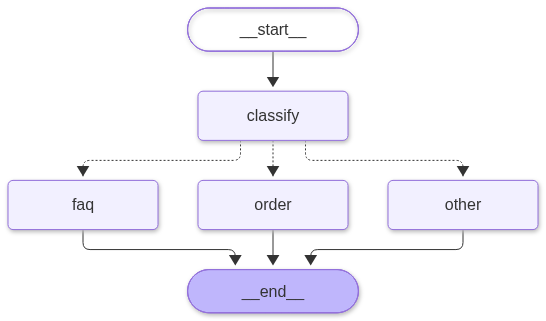

In [38]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain.agents import create_agent
from IPython.display import Image, display

class BakeryState(TypedDict):
    message: str
    intent: str
    reply: str

class Intent(BaseModel):
    intent: Literal["order", "faq", "other"] = Field(
        description="order = wants to buy or book cakes; faq = asks about prices, timings or "
                    "policies; other = greetings or anything unrelated to the bakery"
    )

classifier = llm.with_structured_output(Intent)

FAQ_PROMPT = """You answer questions for Sweet Crumbs Home Bakery.
Use get_price for prices, is_open for timings and search_faq for policies. Never guess.
If the answer isn't found, say "I'll check with the owner." Under 50 words."""

ORDER_PROMPT = """You take cake orders for Sweet Crumbs Home Bakery.
Use get_price for totals. Before log_order, make sure you have name, item, quantity and
pickup date; ask for anything missing. After saving, read the order back. Under 60 words."""

faq_agent = create_agent(model=llm, tools=[search_faq, get_price, is_open], system_prompt=FAQ_PROMPT)
order_agent = create_agent(model=llm, tools=[get_price, log_order], system_prompt=ORDER_PROMPT)

def classify(state: BakeryState) -> dict:
    return {"intent": classifier.invoke(state["message"]).intent}

def ask_agent(agent, message: str) -> str:
    result = agent.invoke({"messages": [{"role": "user", "content": message}]})
    return result["messages"][-1].content

def answer_faq(state: BakeryState) -> dict:
    return {"reply": ask_agent(faq_agent, state["message"])}

def take_order(state: BakeryState) -> dict:
    return {"reply": ask_agent(order_agent, state["message"])}

def other(state: BakeryState) -> dict:
    return {"reply": "Hello from Sweet Crumbs! I can help with cakes, prices, orders and our policies."}

def route(state: BakeryState) -> str:
    return state["intent"]

builder = StateGraph(BakeryState)
builder.add_node("classify", classify)
builder.add_node("faq", answer_faq)
builder.add_node("order", take_order)
builder.add_node("other", other)

builder.add_edge(START, "classify")
builder.add_conditional_edges("classify", route, {"order": "order", "faq": "faq", "other": "other"})
builder.add_edge("faq", END)
builder.add_edge("order", END)
builder.add_edge("other", END)

graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [39]:
tests = [
    "Do you deliver to my area?",
    "I'm Ravi, book 2 eggless plum cakes for 24 Dec",
    "Good morning!",
    "Is the plum cake nut-free?"
]

for msg in tests:
    print("\nCustomer:", msg)
    for step in graph.stream({"message": msg}, stream_mode="updates"):
        print("  ", step)


Customer: Do you deliver to my area?
   {'classify': {'intent': 'faq'}}
   {'faq': {'reply': 'We deliver within 5\u202fkm of the bakery. Delivery costs Rs\u202f50, free for orders above Rs\u202f1,000. Regular orders need 24\u202fhours’ notice.'}}

Customer: I'm Ravi, book 2 eggless plum cakes for 24 Dec
   {'classify': {'intent': 'order'}}
   {'order': {'reply': 'Your order is confirmed: 2 eggless plum cakes for Ravi, pickup on 24 Dec. Total Rs\u202f1000. Let me know if anything else is needed!'}}

Customer: Good morning!
   {'classify': {'intent': 'other'}}
   {'other': {'reply': 'Hello from Sweet Crumbs! I can help with cakes, prices, orders and our policies.'}}

Customer: Is the plum cake nut-free?
   {'classify': {'intent': 'faq'}}
   {'faq': {'reply': 'No, the plum cake contains nuts.'}}


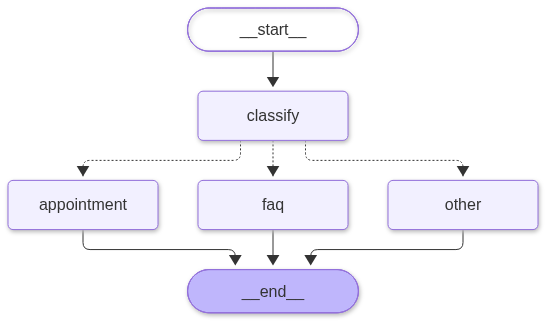

In [40]:
class ClinicState(TypedDict):
    message: str
    intent: str
    reply: str

class ClinicIntent(BaseModel):
    intent: Literal["appointment", "faq", "other"] = Field(
        description=(
            "appointment = patient wants to book or schedule a clinic visit; "
            "faq = patient asks about branch timings, consultation fees, medicine costs, diet rules, or clinic policies; "
            "other = greetings or unrelated messages"
        )
    )

clinic_classifier = llm.with_structured_output(ClinicIntent)

CLINIC_FAQ_PROMPT = """You answer patient questions for Surya Homoeo Clinic.
Use get_branch_timings for hours, estimate_clinic_cost for fees/medicine costs, and search_clinic_faq for policies/diet/storage.
Never diagnose symptoms or suggest medicines; say "Consult doctor as soon as possible."
If info is not found, say "I'll check with the doctor." Under 50 words."""

CLINIC_BOOKING_PROMPT = """You book patient appointments for Surya Homoeo Clinic.
Use get_branch_timings to verify open days and estimate_clinic_cost if asked about cost.
Before log_appointment, collect patient_name, branch ('kakinada' or 'pithapuram'), day, new_month (True for new/new-month visit, False for same-month follow-up), and medicines_for_month.
After booking, confirm the details clearly. Under 60 words."""

clinic_faq_agent = create_agent(
    model=llm,
    tools=[get_branch_timings, estimate_clinic_cost, search_clinic_faq],
    system_prompt=CLINIC_FAQ_PROMPT
)

clinic_booking_agent = create_agent(
    model=llm,
    tools=[get_branch_timings, estimate_clinic_cost, log_appointment],
    system_prompt=CLINIC_BOOKING_PROMPT
)

def classify_clinic(state: ClinicState) -> dict:
    return {"intent": clinic_classifier.invoke(state["message"]).intent}

def handle_clinic_faq(state: ClinicState) -> dict:
    return {"reply": ask_agent(clinic_faq_agent, state["message"])}

def handle_clinic_booking(state: ClinicState) -> dict:
    return {"reply": ask_agent(clinic_booking_agent, state["message"])}

def handle_clinic_other(state: ClinicState) -> dict:
    return {"reply": "Namaste from Surya Homoeo Clinic! I can help with branch timings, fees, clinic policies, or booking an appointment."}

def route_clinic(state: ClinicState) -> str:
    return state["intent"]

clinic_builder = StateGraph(ClinicState)
clinic_builder.add_node("classify", classify_clinic)
clinic_builder.add_node("faq", handle_clinic_faq)
clinic_builder.add_node("appointment", handle_clinic_booking)
clinic_builder.add_node("other", handle_clinic_other)

clinic_builder.add_edge(START, "classify")
clinic_builder.add_conditional_edges(
    "classify",
    route_clinic,
    {"appointment": "appointment", "faq": "faq", "other": "other"}
)
clinic_builder.add_edge("faq", END)
clinic_builder.add_edge("appointment", END)
clinic_builder.add_edge("other", END)

clinic_graph = clinic_builder.compile()
display(Image(clinic_graph.get_graph().draw_mermaid_png()))

In [41]:
clinic_tests = [
    "What are the Kakinada branch timings on Wednesday?",
    "Book a new month appointment for Tharun at Kakinada on Wednesday with 1 month medicine.",
    "Can I drink coffee while taking homeopathy medicines?",
    "Good evening!"
]

for msg in clinic_tests:
    print("\nPatient:", msg)
    for step in clinic_graph.stream({"message": msg}, stream_mode="updates"):
        print("  ", step)


Patient: What are the Kakinada branch timings on Wednesday?
   {'classify': {'intent': 'faq'}}
   {'faq': {'reply': 'Kakinada branch is open from 10:00\u202fAM to 2:30\u202fPM on Wednesdays.'}}

Patient: Book a new month appointment for Tharun at Kakinada on Wednesday with 1 month medicine.
   {'classify': {'intent': 'appointment'}}
   {'appointment': {'reply': 'Your appointment is confirmed:  \n**Tharun** – Kakinada branch, Wednesday, new‑month visit with 1 month’s medicines.  \nEstimated cost: ₹900‑₹1100 (depends on the health issue).  \nSee you then!'}}

Patient: Can I drink coffee while taking homeopathy medicines?
   {'classify': {'intent': 'other'}}
   {'other': {'reply': 'Namaste from Surya Homoeo Clinic! I can help with branch timings, fees, clinic policies, or booking an appointment.'}}

Patient: Good evening!
   {'classify': {'intent': 'other'}}
   {'other': {'reply': 'Namaste from Surya Homoeo Clinic! I can help with branch timings, fees, clinic policies, or booking an appo